# 🔗 Live Deployment Link: **PASTE YOUR OWN STREAMLIT URL HERE AFTER DEPLOYING** (e.g. `https://<your-app-name>.streamlit.app`)

# Heart Disease Prediction System
**Course:** AIC354 Machine Learning — Assignment 2, Task 2  
**Student name / Reg. no.:** ______________________  
Built by adapting the instructor's Titanic Passenger Survival Prediction notebook (same steps, same Label Encoding + SVC approach).

## Introduction

**Definition** — A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from four patient attributes.

**Dataset** — UCI Heart Disease dataset (https://archive.ics.uci.edu/dataset/45/heart+disease). We use **`processed.cleveland.data`** (Cleveland Clinic, 303 patients, the 14-attribute version). It is the file used in essentially all published experiments (see `heart-disease.names`); the other three sites (Hungarian, Switzerland, VA Long Beach) have far more missing values.

## Input and Output

### Inputs (exactly four attributes)

| Attribute | Original UCI column | Possible Values |
|---|---|---|
| **Sex** | `sex` | Female, Male |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **ExerciseAngina** | `exang` | No, Yes |
| **Thal** | `thal` | Normal, Fixed Defect, Reversible Defect |

### Output

| Output Attribute | Possible Values |
|---|---|
| **HeartDisease** (from `num`) | Yes (num = 1–4), No (num = 0) |

### Why these four attributes?
- **Chest pain type (`cp`)**: the symptom a doctor asks about first; "asymptomatic" chest pain is, surprisingly, strongly linked to disease in this data.
- **Exercise-induced angina (`exang`)**: chest pain during exercise is a classic warning sign of reduced blood flow to the heart.
- **Thal (`thal`)**: result of a thallium stress test of blood flow to the heart; a reversible/fixed defect is a strong disease indicator.
- **Sex (`sex`)**: disease rates differ clearly between men and women in this dataset.

All four are *categorical* (words/categories rather than free numbers), exactly like the Titanic inputs (PClass, Gender, Sibling, Embarked), so the instructor's Label Encoding workflow carries over unchanged. They were chosen on medical meaning and data quality (few missing values), **not** by comparing test-set scores.

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction (select the 4 inputs)
- Step 5: Label Encoding the Sample Data
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App
- Conclusion

### Step 1: Import Libraries

In [1]:
"""
Purpose: import libraries for data handling, label encoding, splitting,
SVM training, evaluation, saving the model, and displaying results.
"""
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data
The UCI file `processed.cleveland.data` is **not a normal CSV**: it has no header row, and missing values are written as `?`. We therefore supply the 14 column names from `heart-disease.names` and tell pandas that `?` means missing.

In [2]:
# Column names taken from heart-disease.names (the 14 attributes used in published experiments)
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Read the file: no header row, '?' marks missing values
raw_data = pd.read_csv("processed.cleveland.data", header=None,
                       names=column_names, na_values="?")

print("\n\nRaw UCI Data (first 10 rows):")
print("=============================\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(raw_data.head(10))



Raw UCI Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0

### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
print("\n\nAttributes in Raw Data:")
print("=======================\n")
print(raw_data.columns)

print("\n\nNumber of Instances in Raw Data:", raw_data["age"].count())
print("========================================\n")

print("Data types:")
print(raw_data.dtypes)

print("\nMissing values per column:")
print(raw_data.isnull().sum())

print("\nOriginal target 'num' (0 = no disease, 1-4 = disease of increasing severity):")
print(raw_data["num"].value_counts().sort_index())



Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')


Number of Instances in Raw Data: 303

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Original target 'num' (0 = no disease, 1-4 = disease of increasing severity):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
Unlike the Titanic toy data, this data is **not** already pre-processed, so three steps are needed:
1. **Target:** the original `num` has values 0–4. As in all published experiments, we turn it into a yes/no problem: `0 → No`, `1–4 → Yes`.
2. **Readable categories:** the four chosen inputs are numeric codes (e.g. `cp = 4`). We replace them with the words from `heart-disease.names` so the data looks just like the Titanic data (words → Label Encoder).
3. **Missing values:** `thal` has missing values. Rows with a missing value in any of the four chosen attributes are removed (only 2 rows). `ca` also has missing values, but we do not use `ca`.

In [4]:
# 1. Binary target
raw_data["HeartDisease"] = raw_data["num"].apply(lambda v: "Yes" if v > 0 else "No")

# 2. Replace numeric codes with the category names from heart-disease.names
sex_map   = {0: "Female", 1: "Male"}
cp_map    = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-Anginal Pain", 4: "Asymptomatic"}
exang_map = {0: "No", 1: "Yes"}
thal_map  = {3.0: "Normal", 6.0: "Fixed Defect", 7.0: "Reversible Defect"}

readable = pd.DataFrame({
    "Sex":            raw_data["sex"].map(sex_map),
    "ChestPain":      raw_data["cp"].map(cp_map),
    "ExerciseAngina": raw_data["exang"].map(exang_map),
    "Thal":           raw_data["thal"].map(thal_map),   # '?' stays NaN
    "HeartDisease":   raw_data["HeartDisease"],
})

# 3. Handle missing values: drop rows with a missing value in the selected attributes
print("Missing values in the four selected attributes + target:")
print(readable.isnull().sum())
sample_data = readable.dropna().reset_index(drop=True)
print("\nRows before:", len(readable), "| rows after dropping missing:", len(sample_data))

Missing values in the four selected attributes + target:
Sex               0
ChestPain         0
ExerciseAngina    0
Thal              2
HeartDisease      0
dtype: int64

Rows before: 303 | rows after dropping missing: 301


### Step 4: Feature Extraction
We select **exactly four input attributes** — `Sex`, `ChestPain`, `ExerciseAngina`, `Thal` — and the target `HeartDisease` as the last column (same layout as Titanic: inputs first, output last). The original target `num` is **not** among the inputs.

In [5]:
input_attributes = ["Sex", "ChestPain", "ExerciseAngina", "Thal"]
output_attribute = "HeartDisease"

sample_data = sample_data[input_attributes + [output_attribute]]
assert len(input_attributes) == 4

print("\n\nSample Data (first 10 rows):")
print("============================\n")
print(sample_data.head(10))
print("\nNumber of instances:", len(sample_data))
print("\nClass balance:\n", sample_data["HeartDisease"].value_counts())
sample_data.to_csv("sample-data.csv", index=False, header=True)



Sample Data (first 10 rows):

      Sex         ChestPain ExerciseAngina               Thal HeartDisease
0    Male    Typical Angina             No       Fixed Defect           No
1    Male      Asymptomatic            Yes             Normal          Yes
2    Male      Asymptomatic            Yes  Reversible Defect          Yes
3    Male  Non-Anginal Pain             No             Normal           No
4  Female   Atypical Angina             No             Normal           No
5    Male   Atypical Angina             No             Normal           No
6  Female      Asymptomatic             No             Normal          Yes
7  Female      Asymptomatic            Yes             Normal           No
8    Male      Asymptomatic             No  Reversible Defect          Yes
9    Male      Asymptomatic            Yes  Reversible Defect          Yes

Number of instances: 301

Class balance:
 HeartDisease
No     163
Yes    138
Name: count, dtype: int64


### Step 5: Label Encoding the Sample Data (Input and Output converted to numeric representation)
#### Step 5.1: Train the Label Encoder

In [6]:
# Fixed category lists for each attribute (all possible values, same idea as Titanic)
sex            = pd.DataFrame({"Sex": ["Female", "Male"]})
chestpain      = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
thal           = pd.DataFrame({"Thal": ["Normal", "Fixed Defect", "Reversible Defect"]})
heartdisease   = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder            = LabelEncoder()
chestpain_label_encoder      = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
thal_label_encoder           = LabelEncoder()
heartdisease_label_encoder   = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
thal_label_encoder.fit(np.ravel(thal))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

for name, enc in [("Sex", sex_label_encoder), ("ChestPain", chestpain_label_encoder),
                  ("ExerciseAngina", exerciseangina_label_encoder), ("Thal", thal_label_encoder),
                  ("HeartDisease", heartdisease_label_encoder)]:
    print(name, "->", {c: int(i) for i, c in enumerate(enc.classes_)})

Sex -> {'Female': 0, 'Male': 1}
ChestPain -> {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-Anginal Pain': 2, 'Typical Angina': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
Thal -> {'Fixed Defect': 0, 'Normal': 1, 'Reversible Defect': 2}
HeartDisease -> {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [7]:
sample_data_encoded_output = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding (first 10 rows):")
print("============================================================\n")
sample_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heartdisease"]].head(10))

sample_data_encoded_output[["HeartDisease"]] = sample_data[["encoded_heartdisease"]]
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding (first 10 rows):

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [8]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_sex"]            = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded_output["encoded_chestpain"]      = chestpain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_exerciseangina"] = exerciseangina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])
sample_data_encoded_output["encoded_thal"]           = thal_label_encoder.transform(sample_data_encoded_output["Thal"])

sample_data_encoded[["Sex", "ChestPain", "ExerciseAngina", "Thal", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_sex", "encoded_chestpain", "encoded_exerciseangina", "encoded_thal", "HeartDisease"]]

print("\n\nSample Data after Label Encoding (first 10 rows):")
print("=================================================\n")
print(sample_data_encoded.head(10))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding (first 10 rows):

   Sex  ChestPain  ExerciseAngina  Thal  HeartDisease
0    1          3               0     0             0
1    1          0               1     1             1
2    1          0               1     2             1
3    1          2               0     1             0
4    0          1               0     1             0
5    1          1               0     1             0
6    0          0               0     1             1
7    0          0               1     1             0
8    1          0               0     2             1
9    1          0               1     2             1


### Step 6: Execute the Training Phase
#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [9]:
# Same split as the instructor's Titanic notebook: 80% / 20%, random_state=0, shuffle=False
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=0, shuffle=False)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)
print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (240, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [10]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)
print("Input columns:", list(input_vector_train.columns))

Input vectors (train) shape: (240, 4)
Output labels (train) shape: (240,)
Input columns: ['Sex', 'ChestPain', 'ExerciseAngina', 'Thal']


#### Step 6.3: Train the Support Vector Classifier

In [11]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")
svc_model = svm.SVC(gamma="auto", random_state=0)   # same settings as the Titanic notebook
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model
We save the trained model **and** the label encoders (the app needs the same encoders to convert user input exactly as in training).

In [12]:
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

encoders = {
    "Sex": sex_label_encoder,
    "ChestPain": chestpain_label_encoder,
    "ExerciseAngina": exerciseangina_label_encoder,
    "Thal": thal_label_encoder,
    "HeartDisease": heartdisease_label_encoder,
}
pickle.dump(encoders, open("heart_label_encoders.pkl", "wb"))
print("Saved: heart_label_encoders.pkl")

Saved: heart_svc_trained_model.pkl
Saved: heart_label_encoders.pkl


### Step 7: Execute the Testing Phase
#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [13]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [14]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model
#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [15]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(model_predictions)



Predictions Returned by heart_svc_trained_model:

     Sex  ChestPain  ExerciseAngina  Thal  HeartDisease  Predictions
240    0          1               0     1             0            0
241    0          0               0     1             0            0
242    1          3               0     1             1            0
243    0          2               0     1             0            0
244    1          0               0     1             1            0
245    1          0               0     2             1            1
246    1          0               1     1             1            1
247    1          0               0     2             1            1
248    1          1               0     1             0            0
249    1          0               1     0             0            1
250    1          0               0     2             1            1
251    1          0               1     2             0            1
252    0          2               0     1          

### Step 7.4: Calculate the Accuracy Score

In [16]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:



                precision    recall  f1-score   support

No Disease (0)       0.68      0.93      0.79        30
   Disease (1)       0.90      0.58      0.71        31

      accuracy                           0.75        61
     macro avg       0.79      0.76      0.75        61
  weighted avg       0.79      0.75      0.75        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     28                   2
Actual: Disease                        13                  18


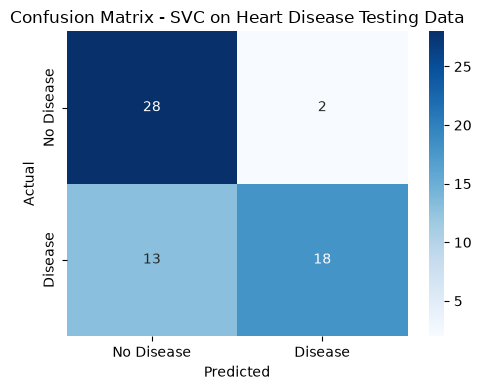

In [17]:
print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Disease (0)", "Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\nConfusion Matrix:")
print("==================\n")
print(pd.DataFrame(conf_matrix,
                   index=["Actual: No Disease", "Actual: Disease"],
                   columns=["Predicted: No Disease", "Predicted: Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout(); plt.show()

### Step 8: Execute the Application Phase
#### Step 8.1: Take Input from User
Exactly **four** values are taken. A demo patient is pre-filled so the notebook runs top-to-bottom; to type your own values, replace the four lines with `input()` calls, e.g. `sex_input = input("Sex (Female, Male): ").strip()`.

In [18]:
sex_input            = "Male"
chestpain_input      = "Asymptomatic"
exerciseangina_input = "Yes"
thal_input           = "Reversible Defect"

print(f"Sex: {sex_input}, ChestPain: {chestpain_input}, ExerciseAngina: {exerciseangina_input}, Thal: {thal_input}")

Sex: Male, ChestPain: Asymptomatic, ExerciseAngina: Yes, Thal: Reversible Defect


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [19]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chestpain_input],
    "ExerciseAngina": [exerciseangina_input],
    "Thal": [thal_input],
})
print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

    Sex     ChestPain ExerciseAngina               Thal
0  Male  Asymptomatic            Yes  Reversible Defect


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)
Here the encoders are loaded **from the saved file**, proving inference uses the same preprocessing as training.

In [20]:
saved_encoders = pickle.load(open("heart_label_encoders.pkl", "rb"))

unseen_data_features = user_input.copy()
for col in ["Sex", "ChestPain", "ExerciseAngina", "Thal"]:
    unseen_data_features[col] = saved_encoders[col].transform(user_input[col])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)
assert list(unseen_data_features.columns) == list(input_vector_train.columns)   # same 4 columns, same order



User Input Encoded Feature Vector:

   Sex  ChestPain  ExerciseAngina  Thal
0    1          0               1     2


### Step 8.4: Load the Saved Model

In [21]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction
#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [22]:
predicted_disease = model.predict(unseen_data_features)

if predicted_disease == 1:
    prediction = "HEART DISEASE LIKELY"
if predicted_disease == 0:
    prediction = "NO HEART DISEASE LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase
No real users or domain experts have tested this model yet, so no feedback is invented here. Based on the evaluation above, potential improvements are listed below.

In [23]:
improvements = [
    "Use more attributes (e.g. age, thalach, oldpeak, ca) to see if accuracy improves - the assignment limits this version to four inputs",
    "The dataset is small (about 300 patients, one hospital), so results on a 20% test split (about 60 patients) are noisy; try cross-validation",
    "Compare the false negatives (disease missed) in the confusion matrix - missing a sick patient is costlier than a false alarm",
    "Add data from the other three UCI hospitals (more missing values, but more patients)",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use more attributes (e.g. age, thalach, oldpeak, ca) to see if accuracy improves - the assignment limits this version to four inputs
2. The dataset is small (about 300 patients, one hospital), so results on a 20% test split (about 60 patients) are noisy; try cross-validation
3. Compare the false negatives (disease missed) in the confusion matrix - missing a sick patient is costlier than a false alarm
4. Add data from the other three UCI hospitals (more missing values, but more patients)


## Step 10: Deploy Your Model as a Public Web App

Same process as the instructor's Titanic tutorial (Streamlit Community Cloud). Files needed in your GitHub repo: `app.py`, `requirements.txt`, `runtime.txt`, `heart_svc_trained_model.pkl`, `heart_label_encoders.pkl`.

1. Create a **public** GitHub repository (e.g. `heart-disease-app`) and upload those five files at the repo root.
2. Go to https://share.streamlit.io and sign in with GitHub.
3. **Create app → Deploy a public app from GitHub**; choose your repo, branch `main`, main file `app.py`; click **Deploy**.
4. If the build fails with a missing-package error, open **Settings → General → Python version** and choose 3.11 (also see Step 10.6 of the Titanic notebook).
5. Copy your `https://<your-app>.streamlit.app` URL and paste it into the **first cell** of this notebook.

Run locally first with: `streamlit run app.py`

## Conclusion

In [24]:
print(f"Final model: Support Vector Classifier (gamma='auto') on 4 inputs: {input_attributes}")
print(f"Training rows: {len(training_data_encoded)} | Testing rows: {len(testing_data_encoded)}")
print(f"Accuracy on the held-out test set: {model_accuracy_score:.2f}")

Final model: Support Vector Classifier (gamma='auto') on 4 inputs: ['Sex', 'ChestPain', 'ExerciseAngina', 'Thal']
Training rows: 240 | Testing rows: 61
Accuracy on the held-out test set: 0.75


The notebook follows the instructor's Titanic workflow (Label Encoding + SVC, 80/20 split, pickle save/load, Streamlit deployment) on the Cleveland heart disease data using four categorical inputs. The accuracy printed above is the actual result of running this notebook. It comes from a small test set (about 60 patients), so it is only a rough indicator; this tool is for learning and is **not** a medical diagnostic.